# Libs

In [1]:
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import sklearn
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Plot Style

In [2]:
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e5e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#52514e",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

COLOR_EXISTING = "#2a78d6"  # categorical slot 1 (blue)
COLOR_NEW = "#eb6834"  # categorical slot 2 (orange)
COLOR_NEUTRAL = "#8a8a85"  # muted reference lines
SEQUENTIAL_BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab"]

# Helpers

In [3]:
def apply_episode_cooldown(active_grid, cooldown_days):
    """Select one training snapshot per eligibility episode.

    Starting from a customer's first active snapshot date, the next
    training snapshot is the first later active date at least
    cooldown_days after it, and so on. This removes near-duplicate,
    overlapping snapshots from the training population. (Reused
    unchanged from notebooks/01_data_understanding.ipynb and
    notebooks/03_data_preparation.ipynb.)

    Args:
        active_grid: Active rows with customer_id and
            snapshot_date columns.
        cooldown_days: Minimum gap in days between two training
            snapshots of the same customer (C).

    Returns:
        The subset of active_grid rows selected as training
        snapshots.
    """
    cooldown = pd.Timedelta(days=cooldown_days)
    ordered = active_grid.sort_values(["customer_id", "snapshot_date"])
    selected_index = []
    for _, rows in ordered.groupby("customer_id"):
        next_allowed = None
        for row in rows.itertuples():
            allowed = next_allowed is None or row.snapshot_date >= (
                next_allowed
            )
            if allowed:
                selected_index.append(row.Index)
                next_allowed = row.snapshot_date + cooldown
    return active_grid.loc[selected_index]

In [4]:
def precision_at_k(y_true, scores, k_frac):
    """Precision within the top k_frac of ranked scores.

    Args:
        y_true: Array-like of 0/1 true churn labels.
        scores: Array-like of churn-risk scores, aligned with
            y_true (higher = more likely to churn).
        k_frac: Fraction of rows treated as "targeted" (e.g. 0.1
            for the top 10%).

    Returns:
        The churn rate among the top k_frac of rows by score.
    """
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    k = max(int(round(len(scores) * k_frac)), 1)
    top_idx = np.argsort(-scores)[:k]
    return y_true[top_idx].mean()


def lift_at_k(y_true, scores, k_frac):
    """Lift of the top k_frac segment over the overall base rate."""
    y_true = np.asarray(y_true)
    base_rate = y_true.mean()
    return precision_at_k(y_true, scores, k_frac) / base_rate


def gain_at_k(y_true, scores, k_frac):
    """Share of all positives captured within the top k_frac."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    k = max(int(round(len(scores) * k_frac)), 1)
    top_idx = np.argsort(-scores)[:k]
    return y_true[top_idx].sum() / y_true.sum()


def evaluate_ranking(y_true, scores, k_frac=0.10):
    """Pooled predictive + ranking metrics at one operating point.

    Metrics are pooled across all rows passed in, not computed per
    scoring week and averaged -- that per-week treatment is left to
    Section 6.3. This is enough to select between candidate models.

    Args:
        y_true: Array-like of 0/1 true churn labels.
        scores: Array-like of churn-risk scores.
        k_frac: Operating top-K fraction for ranking metrics.

    Returns:
        A dict with roc_auc, pr_auc, precision_at_k, lift_at_k,
        gain_at_k.
    """
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    pct = int(k_frac * 100)
    return {
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        f"precision_at_{pct}": precision_at_k(y_true, scores, k_frac),
        f"lift_at_{pct}": lift_at_k(y_true, scores, k_frac),
        f"gain_at_{pct}": gain_at_k(y_true, scores, k_frac),
    }

In [5]:
LOG_FEATURES = [
    "monetary_so_far", "avg_order_value_so_far", "tenure_days",
    "mean_gap_so_far", "recency_to_typical_gap", "activity_last_90d",
    "distinct_products_so_far", "cancel_count_so_far",
    "frequency_so_far",
]


def prepare_features(df, features):
    """Select feature columns, log1p-transforming the skewed ones.

    Several engineered features (revenue, counts, ratios) are
    extremely right-skewed (Section 5.5's known instability note) -- even after standard scaling, a single
    extreme outlier can still overflow Logistic Regression's linear
    predictor. log1p is deterministic (no fitted parameters), so
    applying it introduces no leakage.

    Args:
        df: DataFrame containing `features`.
        features: List of feature column names to select.

    Returns:
        A new DataFrame with the same columns, skewed ones log1p-
        transformed.
    """
    X = df[features].copy()
    for col in features:
        if col in LOG_FEATURES:
            X[col] = np.log1p(X[col])
    return X


def fit_and_score(model, features, train_df, eval_df,
                   sample_weight=None):
    """Fit a median-imputed, standardized model and score eval_df.

    The imputer and scaler are fit on train_df only (Section
    5.6 leakage rule: aggregates that depend on the data are
    fitted on the training period only). Scaling (after log1p-
    transforming the most skewed features in prepare_features)
    matters most for Logistic Regression -- feature magnitudes here
    range from single digits (recency_days) to the hundreds of
    thousands (monetary_so_far); it is harmless for the
    scale-invariant tree models, so it is applied uniformly.

    Args:
        model: An unfitted scikit-learn-compatible classifier.
        features: List of feature column names.
        train_df: Training rows (must have a churn column).
        eval_df: Rows to score (must have a churn column).
        sample_weight: Optional per-row training weights, aligned
            with train_df.

    Returns:
        A tuple (metrics dict from evaluate_ranking, (imputer,
        scaler, fitted model)).
    """
    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(prepare_features(train_df, features))
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    y_train = train_df["churn"]
    if sample_weight is None:
        model.fit(X_train, y_train)
    else:
        model.fit(X_train, y_train, sample_weight=sample_weight)

    X_eval = scaler.transform(
        imputer.transform(prepare_features(eval_df, features))
    )
    scores = model.predict_proba(X_eval)[:, 1]
    metrics = evaluate_ranking(eval_df["churn"], scores)
    return metrics, (imputer, scaler, model)


def build_model(name, params):
    """Construct a fresh, unfitted classifier.

    Args:
        name: One of "logistic_regression", "random_forest",
            "xgboost".
        params: Dict of hyperparameters passed to the constructor.

    Returns:
        An unfitted scikit-learn-compatible classifier.
    """
    if name == "logistic_regression":
        return LogisticRegression(
            max_iter=1000, solver="liblinear", **params
        )
    if name == "random_forest":
        return RandomForestClassifier(
            random_state=0, n_jobs=-1, **params
        )
    if name == "xgboost":
        return XGBClassifier(
            eval_metric="logloss", random_state=0, n_jobs=-1, **params
        )
    raise ValueError(f"Unknown algorithm: {name}")

In [6]:
def predict_scores(fitted, features, df):
    """Churn-risk scores for df from a fit_and_score result.

    Args:
        fitted: The (imputer, scaler, model) tuple returned by
            fit_and_score.
        features: List of feature column names the model was fit on.
        df: Rows to score.

    Returns:
        A numpy array of predicted churn probabilities.
    """
    imputer, scaler, model = fitted
    X = scaler.transform(imputer.transform(prepare_features(df, features)))
    return model.predict_proba(X)[:, 1]


def customer_balanced_weights(df):
    """Per-row training weight 1 / (customer's row count in df).

    Every customer gets the same total weight however many weekly
    rows they contribute (Section 5.3's weighted training scheme).
    Recomputed on each training pool, since a customer's row count
    depends on the window.

    Args:
        df: Rows with a customer_id column.

    Returns:
        A Series of weights aligned with df.
    """
    counts = df.groupby("customer_id")["customer_id"].transform("size")
    return 1.0 / counts


def bootstrap_diff(y_true, scores_a, scores_b, customer_ids, metric_fn,
                   n_boot=500, seed=0):
    """Customer-level bootstrap of metric(scores_b) - metric(scores_a).

    Rows of the same customer across weeks are correlated, so whole
    customers are resampled with replacement rather than rows.

    Args:
        y_true: Array-like of 0/1 true churn labels.
        scores_a: Scores of the reference candidate.
        scores_b: Scores of the challenger, aligned with scores_a.
        customer_ids: Customer id of each row.
        metric_fn: Function (y_true, scores) -> float.
        n_boot: Number of bootstrap resamples.
        seed: Random seed.

    Returns:
        A dict with mean, ci_low, ci_high (95%) and p_gt_0 (share of
        resamples where B beats A).
    """
    y_true = np.asarray(y_true)
    scores_a = np.asarray(scores_a)
    scores_b = np.asarray(scores_b)
    rows_by_customer = (
        pd.Series(np.arange(len(y_true))).groupby(np.asarray(customer_ids))
        .apply(np.array)
    )
    customers = rows_by_customer.index.to_numpy()
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        picked = rng.choice(customers, size=len(customers), replace=True)
        idx = np.concatenate(rows_by_customer.loc[picked].to_numpy())
        diffs.append(
            metric_fn(y_true[idx], scores_b[idx])
            - metric_fn(y_true[idx], scores_a[idx])
        )
    diffs = np.array(diffs)
    return {
        "mean": diffs.mean(),
        "ci_low": np.percentile(diffs, 2.5),
        "ci_high": np.percentile(diffs, 97.5),
        "p_gt_0": (diffs > 0).mean(),
    }


def tune_c(features, train_df, eval_df, sample_weight=None):
    """Validation metrics of Logistic Regression over LR_C_GRID.

    Args:
        features: List of feature column names.
        train_df: Training rows.
        eval_df: Validation rows.
        sample_weight: Optional per-row training weights.

    Returns:
        A DataFrame with one row per C value and the
        evaluate_ranking metrics as columns.
    """
    rows = []
    for c in LR_C_GRID:
        metrics, _ = fit_and_score(
            build_model("logistic_regression", {"C": c}), features,
            train_df, eval_df, sample_weight=sample_weight,
        )
        rows.append({"C": c, **metrics})
    return pd.DataFrame(rows)

In [7]:
def fit_calibration_offset(probabilities, y_true):
    """Log-odds shift that matches the mean prediction to the churn rate.

    Training with per-customer weights (1/n_i) lifts the effective
    churn rate the model learns, so its raw probabilities overestimate
    risk on unweighted rows. The offset delta solves
    mean(expit(logit(p) - delta)) = mean(y) on the training rows
    themselves (calibration-in-the-large). A single intercept shift,
    so rankings are unchanged; fitted on training data only.

    Args:
        probabilities: Raw predicted churn probabilities on the
            training rows.
        y_true: Array-like of 0/1 true churn labels of the same rows.

    Returns:
        The offset to subtract from the log-odds.
    """
    logits = logit(np.clip(np.asarray(probabilities), 1e-12, 1 - 1e-12))
    target = np.mean(y_true)
    return brentq(lambda d: expit(logits - d).mean() - target, -10, 10)


def corrected_brier(y_true, probabilities, offset):
    """Brier score of calibrated probabilities.

    Args:
        y_true: Array-like of 0/1 true churn labels.
        probabilities: Raw predicted churn probabilities.
        offset: Log-odds shift from fit_calibration_offset.

    Returns:
        The Brier score of expit(logit(p) - offset).
    """
    p = np.clip(np.asarray(probabilities), 1e-12, 1 - 1e-12)
    return brier_score_loss(y_true, expit(logit(p) - offset))


def band_shares(bands, n_bands):
    """Share of rows in each risk band 1..n_bands (0 for empty bands)."""
    counts = pd.Series(bands).value_counts()
    return counts.reindex(range(1, n_bands + 1), fill_value=0) / len(bands)


def hhi(bands, n_bands):
    """Herfindahl-Hirschman Index of the rows' risk-band distribution.

    Sum of squared band shares: 1 / n_bands when rows spread evenly,
    1 when every row falls in a single band.

    Args:
        bands: Array-like of risk bands (1..n_bands).
        n_bands: Number of bands.

    Returns:
        The HHI as a float.
    """
    return float((band_shares(bands, n_bands) ** 2).sum())


def csi(bands, reference_shares, floor=1e-6):
    """Stability index of the risk-band distribution vs. a reference.

    sum((actual - expected) * ln(actual / expected)) over bands; empty
    bands are floored so the log stays finite. Rule of thumb: < 0.10
    stable, 0.10-0.25 moderate shift, > 0.25 major shift.

    Args:
        bands: Array-like of risk bands (1..len(reference_shares)).
        reference_shares: Band shares of the reference period.
        floor: Minimum share used in place of 0.

    Returns:
        The index as a float.
    """
    expected = np.maximum(np.asarray(reference_shares), floor)
    actual = np.maximum(
        band_shares(bands, len(expected)).to_numpy(), floor
    )
    return float(((actual - expected) * np.log(actual / expected)).sum())

# Load

In [8]:
modeling_dataset = pd.read_parquet(
    "../data/processed/modeling_dataset_h90.parquet"
)
modeling_dataset.shape

(208764, 25)

**Chosen parameters (inherited from Chapters 4-5).** $H = 90$
days, $R_{\max} = 136$ days (P90). The training-episode cooldown
$C = 90$ days is used only for the episode-sampled comparison
scheme in 6.1. `LR_C_GRID` is the regularization grid tuned for
Logistic Regression wherever it is compared (6.1, 6.2). The 10
risk bands (6.3) are cut at the validation-period deciles of the
calibrated churn probability.

In [9]:
H = 90
COOLDOWN_DAYS = H
K_FRAC = 0.10

RFM_FEATURES = ["recency_days", "frequency_so_far", "monetary_so_far"]
EXTENDED_FEATURES = RFM_FEATURES + [
    "avg_order_value_so_far", "tenure_days", "mean_gap_so_far",
    "recency_to_typical_gap", "activity_last_90d",
]
FULL_FEATURES = EXTENDED_FEATURES + [
    "distinct_products_so_far", "cancel_count_so_far",
    "cancel_value_share_so_far",
]
FEATURE_SETS = {
    "RFM": RFM_FEATURES,
    "Extended": EXTENDED_FEATURES,
    "Full": FULL_FEATURES,
}

LR_C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 10.0, 100.0]
MODEL_VERSION = "lr_extended_c0.01_weighted_cal_h90"

N_RISK_BANDS = 10

## 6.1 Model Selection

Estimate $P(\text{Churn} = 1 \mid \text{Customer History at
Snapshot})$ on `data/processed/modeling_dataset_h90.parquet`
(Chapter 5's output; split table in Section 5.6). Every decision is
taken on **validation**, in a fixed order -- training rows, then
features, then algorithm -- and test is not touched until 6.3.

**Rule (fixed before looking at results):** a candidate's gain over
a simpler one counts only if the customer-level bootstrap (500
resamples of whole customers, since a customer's weekly rows are
correlated) 95% CI of the validation **PR-AUC** gap excludes 0;
otherwise the simpler candidate is kept. AUC and the Brier score
of calibrated probabilities (each candidate's mean prediction
matched to its own training churn rate, 6.3) are reported
alongside.

In [10]:
train_df = modeling_dataset[modeling_dataset["split"] == "train"]
train_weights = train_df["sample_weight"]
train_episode_df = train_df[train_df["in_training_sample"]]
val_df = modeling_dataset[modeling_dataset["split"] == "validation"]
test_df = modeling_dataset[modeling_dataset["split"] == "test"]

assert np.allclose(train_weights, customer_balanced_weights(train_df))

print(f"Train (all weekly, weighted): {len(train_df):,} rows of "
      f"{train_df['customer_id'].nunique():,} customers")
print(f"Train (episode-sampled, 6.1 comparison): "
      f"{len(train_episode_df):,} rows")
print(f"Validation: {len(val_df):,} rows")
print(f"Test: {len(test_df):,} rows")
print(f"Train churn rate (unweighted): {train_df['churn'].mean():.1%}")
print(f"Validation churn rate: {val_df['churn'].mean():.1%}")

Train (all weekly, weighted): 61,415 rows of 3,905 customers
Train (episode-sampled, 6.1 comparison): 6,453 rows
Validation: 21,514 rows
Test: 24,252 rows
Train churn rate (unweighted): 43.0%
Validation churn rate: 52.9%


### Baselines

**Random ranking** (uniform random scores) and the **recency rule**
(score = days since last purchase), both without learned
parameters.

In [11]:
rng = np.random.default_rng(0)
random_scores = rng.uniform(size=len(val_df))
recency_scores = val_df["recency_days"].to_numpy()

baseline_results = pd.DataFrame({
    "random": evaluate_ranking(val_df["churn"], random_scores),
    "recency_rule": evaluate_ranking(val_df["churn"], recency_scores),
}).T
baseline_results.round(3)

,roc_auc,pr_auc,precision_at_10,lift_at_10,gain_at_10
random,0.495,0.527,0.535,1.012,0.101
recency_rule,0.673,0.673,0.731,1.382,0.138


### Training rows

**A -- Episode**: one snapshot per customer per 90-day cooldown
(`in_training_sample`), unweighted. **B -- All weekly, weighted**:
every active row, weighted `sample_weight` $= 1/n_i$ so each
customer carries equal total weight (Section 5.3). Both use Logistic
Regression on the Full feature set, each with its own C tuned over
`LR_C_GRID` (weights change the effective regularization).

In [12]:
scheme_inputs = {
    "A_episode": (train_episode_df, None),
    "B_weighted_all": (train_df, train_weights),
}

scheme_grids = {
    name: tune_c(FULL_FEATURES, rows, val_df, sample_weight=weights)
    for name, (rows, weights) in scheme_inputs.items()
}
scheme_best = pd.DataFrame({
    name: grid.loc[grid["pr_auc"].idxmax()]
    for name, grid in scheme_grids.items()
}).T
pd.concat(scheme_grids, names=["scheme"]).round(4)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

C  roc_auc  pr_auc  precision_at_10  lift_at_10  \
scheme                                                                    
A_episode      0    0.001   0.7733  0.7522           0.8029      1.5188   
               1    0.003   0.7736  0.7522           0.8015      1.5162   
               2    0.010   0.7720  0.7504           0.7992      1.5118   
               3    0.030   0.7696  0.7479           0.7899      1.4942   
               4    0.100   0.7678  0.7461           0.7885      1.4915   
               5    0.300   0.7670  0.7455           0.7899      1.4942   
               6    1.000   0.7668  0.7453           0.7903      1.4950   
               7   10.000   0.7667  0.7453           0.7913      1.4968   
               8  100.000   0.7667  0.7453           0.7917      1.4977   
B_weighted_all 0    0.001   0.7759  0.7633           0.8461      1.6006   
               1    0.003   0.7778  0.7663           0.8466      1.6015   
               2    0.010   0.7796  0.7684           0.8475      1.6032   
               3    0.030   0.7805  0.7693           0.8461      1.6006   
               4    0.100   0.7807  0.7696           0.8447      1.5979   
               5    0.300   0.7808  0.7697           0.8452      1.5988   
               6    1.000   0.7809  0.7698           0.8447      1.5979   
               7   10.000   0.7809  0.7698           0.8443      1.5971   
               8  100.000   0.7810  0.7699           0.8452      1.5988   

                  gain_at_10  
scheme                        
A_episode      0      0.1519  
               1      0.1516  
               2      0.1511  
               3      0.1494  
               4      0.1491  
               5      0.1494  
               6      0.1495  
               7      0.1497  
               8      0.1497  
B_weighted_all 0      0.1600  
               1      0.1601  
               2      0.1603  
               3      0.1600  
               4      0.1598  
               5      0.1599  
               6      0.1598  
               7      0.1597  
               8      0.1599

In [13]:
scheme_scores = {}
scheme_offsets = {}
for name, (rows, weights) in scheme_inputs.items():
    _, fitted = fit_and_score(
        build_model("logistic_regression", {"C": scheme_best.loc[name, "C"]}),
        FULL_FEATURES, rows, val_df, sample_weight=weights,
    )
    scheme_scores[name] = predict_scores(fitted, FULL_FEATURES, val_df)
    scheme_offsets[name] = fit_calibration_offset(
        predict_scores(fitted, FULL_FEATURES, rows), rows["churn"]
    )

scheme_bootstrap = pd.DataFrame({
    metric: bootstrap_diff(
        val_df["churn"], scheme_scores["A_episode"],
        scheme_scores["B_weighted_all"], val_df["customer_id"], fn,
    )
    for metric, fn in {
        "pr_auc": average_precision_score,
        "roc_auc": roc_auc_score,
    }.items()
}).T

print("Best C per scheme (validation):")
print(scheme_best[["C", "roc_auc", "pr_auc"]].round(4))
print("\nBootstrap B - A on validation:")
scheme_bootstrap.round(4)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

Best C per scheme (validation):
                      C  roc_auc  pr_auc
A_episode         0.003   0.7736  0.7522
B_weighted_all  100.000   0.7810  0.7699

Bootstrap B - A on validation:


,mean,ci_low,ci_high,p_gt_0
pr_auc,0.0173,0.0107,0.0237,1.0
roc_auc,0.0073,0.0047,0.0098,1.0


In [14]:
use_weighted_scheme = scheme_bootstrap.loc["pr_auc", "ci_low"] > 0
if use_weighted_scheme:
    train_rows, train_sample_weight = train_df, train_weights
else:
    train_rows, train_sample_weight = train_episode_df, None
print(f"Training scheme carried forward: "
      f"{'B_weighted_all' if use_weighted_scheme else 'A_episode'}")

Training scheme carried forward: B_weighted_all


### Feature sets

Three nested sets, each with Logistic Regression and its own C:
**RFM** (recency, frequency, monetary); **Extended** (+ average
order value, tenure, mean inter-purchase gap, recency relative to
that gap, activity in the last 90 days -- the two gap features are
`NaN` for one-time customers and median-imputed on train only);
**Full** (+ distinct products, cancellation count and value share).
The top set falls back to the smallest set it is tied with.

In [15]:
feature_grids = {
    name: tune_c(features, train_rows, val_df,
                 sample_weight=train_sample_weight)
    for name, features in FEATURE_SETS.items()
}
pd.concat(feature_grids, names=["feature_set"]).round(4)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


C  roc_auc  pr_auc  precision_at_10  lift_at_10  \
feature_set                                                            
RFM         0    0.001   0.7789  0.7676           0.8377      1.5847   
            1    0.003   0.7789  0.7675           0.8368      1.5830   
            2    0.010   0.7787  0.7678           0.8373      1.5839   
            3    0.030   0.7785  0.7682           0.8429      1.5944   
            4    0.100   0.7783  0.7684           0.8419      1.5927   
            5    0.300   0.7783  0.7685           0.8433      1.5953   
            6    1.000   0.7782  0.7685           0.8443      1.5971   
            7   10.000   0.7782  0.7685           0.8447      1.5979   
            8  100.000   0.7782  0.7685           0.8447      1.5979   
Extended    0    0.001   0.7746  0.7634           0.8382      1.5856   
            1    0.003   0.7769  0.7670           0.8447      1.5979   
            2    0.010   0.7795  0.7701           0.8475      1.6032   
            3    0.030   0.7806  0.7714           0.8466      1.6015   
            4    0.100   0.7809  0.7716           0.8457      1.5997   
            5    0.300   0.7809  0.7717           0.8466      1.6015   
            6    1.000   0.7810  0.7717           0.8457      1.5997   
            7   10.000   0.7811  0.7717           0.8466      1.6015   
            8  100.000   0.7811  0.7718           0.8466      1.6015   
Full        0    0.001   0.7759  0.7633           0.8461      1.6006   
            1    0.003   0.7778  0.7663           0.8466      1.6015   
            2    0.010   0.7796  0.7684           0.8475      1.6032   
            3    0.030   0.7805  0.7693           0.8461      1.6006   
            4    0.100   0.7807  0.7696           0.8447      1.5979   
            5    0.300   0.7808  0.7697           0.8452      1.5988   
            6    1.000   0.7809  0.7698           0.8447      1.5979   
            7   10.000   0.7809  0.7698           0.8443      1.5971   
            8  100.000   0.7810  0.7699           0.8452      1.5988   

               gain_at_10  
feature_set                
RFM         0      0.1584  
            1      0.1583  
            2      0.1584  
            3      0.1594  
            4      0.1592  
            5      0.1595  
            6      0.1597  
            7      0.1598  
            8      0.1598  
Extended    0      0.1585  
            1      0.1598  
            2      0.1603  
            3      0.1601  
            4      0.1599  
            5      0.1601  
            6      0.1599  
            7      0.1601  
            8      0.1601  
Full        0      0.1600  
            1      0.1601  
            2      0.1603  
            3      0.1600  
            4      0.1598  
            5      0.1599  
            6      0.1598  
            7      0.1597  
            8      0.1599

In [16]:
feature_best = pd.DataFrame({
    name: grid.loc[grid["pr_auc"].idxmax()]
    for name, grid in feature_grids.items()
}).T
feature_scores = {}
feature_offsets = {}
for name, features in FEATURE_SETS.items():
    _, fitted = fit_and_score(
        build_model("logistic_regression", {"C": feature_best.loc[name, "C"]}),
        features, train_rows, val_df, sample_weight=train_sample_weight,
    )
    feature_scores[name] = predict_scores(fitted, features, val_df)
    feature_offsets[name] = fit_calibration_offset(
        predict_scores(fitted, features, train_rows), train_rows["churn"]
    )

top_set = feature_best["pr_auc"].idxmax()
feature_bootstrap = pd.DataFrame({
    f"{top_set} - {name}": bootstrap_diff(
        val_df["churn"], feature_scores[name], feature_scores[top_set],
        val_df["customer_id"], average_precision_score,
    )
    for name in FEATURE_SETS
    if name != top_set
}).T

print("Best C per feature set (validation):")
print(feature_best[["C", "roc_auc", "pr_auc"]].round(4))
print("\nBootstrap PR-AUC gain of the top set over each other set:")
feature_bootstrap.round(4)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

Best C per feature set (validation):
              C  roc_auc  pr_auc
RFM       100.0   0.7782  0.7685
Extended  100.0   0.7811  0.7718
Full      100.0   0.7810  0.7699

Bootstrap PR-AUC gain of the top set over each other set:


,mean,ci_low,ci_high,p_gt_0
Extended - RFM,0.0032,0.0002,0.0063,0.982
Extended - Full,0.0020,-0.0024,0.0059,0.838


In [17]:
selected_set = top_set
for name in FEATURE_SETS:  # ordered smallest first
    if name == top_set:
        break
    if feature_bootstrap.loc[f"{top_set} - {name}", "ci_low"] <= 0:
        selected_set = name
        break
selected_features = FEATURE_SETS[selected_set]
print(f"Top set by validation PR-AUC: {top_set}")
print(f"Selected feature set: {selected_set}")

Top set by validation PR-AUC: Extended
Selected feature set: Extended


### Algorithm

Logistic Regression, Random Forest and XGBoost on the selected
feature set, default hyperparameters, same rows and weights.

In [18]:
default_models = {
    "logistic_regression": LogisticRegression(
        max_iter=1000, solver="liblinear"
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, random_state=0, n_jobs=-1
    ),
    "xgboost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.1,
        eval_metric="logloss", random_state=0, n_jobs=-1,
    ),
}

algorithm_results = {}
algorithm_scores = {}
algorithm_offsets = {}
for name, model in default_models.items():
    metrics, fitted = fit_and_score(
        model, selected_features, train_rows, val_df,
        sample_weight=train_sample_weight,
    )
    algorithm_results[name] = metrics
    algorithm_scores[name] = predict_scores(fitted, selected_features, val_df)
    algorithm_offsets[name] = fit_calibration_offset(
        predict_scores(fitted, selected_features, train_rows),
        train_rows["churn"],
    )

algorithm_comparison = pd.DataFrame(algorithm_results).T
algorithm_comparison[["roc_auc", "pr_auc"]].round(3)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

,roc_auc,pr_auc
logistic_regression,0.781,0.772
random_forest,0.770,0.755
xgboost,0.756,0.745


In [19]:
best_algorithm = algorithm_comparison["pr_auc"].idxmax()
print(f"Best algorithm by validation PR-AUC: {best_algorithm}")

Best algorithm by validation PR-AUC: logistic_regression


### Selection summary

One row per candidate at each step (validation); `selected` marks
the candidate carried forward. `brier_corrected` applies each
candidate's own calibration offset (fitted on its own training
rows), so weighted and unweighted fits compare fairly; the
baselines are rankings, not probabilities, and have no Brier.

In [20]:
selected_at_step = {
    "training_rows": "B_weighted_all" if use_weighted_scheme else "A_episode",
    "features": selected_set,
    "algorithm": best_algorithm,
}
y_val = val_df["churn"]
brier_by_candidate = pd.Series({
    **{("training_rows", name): corrected_brier(
        y_val, scores, scheme_offsets[name]
    ) for name, scores in scheme_scores.items()},
    **{("features", name): corrected_brier(
        y_val, scores, feature_offsets[name]
    ) for name, scores in feature_scores.items()},
    **{("algorithm", name): corrected_brier(
        y_val, scores, algorithm_offsets[name]
    ) for name, scores in algorithm_scores.items()},
})

selection_summary = pd.concat({
    "baseline": baseline_results,
    "training_rows": scheme_best,
    "features": feature_best,
    "algorithm": algorithm_comparison,
}, names=["step", "candidate"])[["roc_auc", "pr_auc"]]
selection_summary["brier_corrected"] = brier_by_candidate
selection_summary["selected"] = [
    selected_at_step.get(step) == name
    for step, name in selection_summary.index
]
selection_summary.round(3)

roc_auc  pr_auc  brier_corrected  selected
step          candidate                                                      
baseline      random                 0.495   0.527              NaN     False
              recency_rule           0.673   0.673              NaN     False
training_rows A_episode              0.774   0.752            0.226     False
              B_weighted_all         0.781   0.770            0.214      True
features      RFM                    0.778   0.769            0.218     False
              Extended               0.781   0.772            0.214      True
              Full                   0.781   0.770            0.214     False
algorithm     logistic_regression    0.781   0.772            0.214      True
              random_forest          0.770   0.755            0.222     False
              xgboost                0.756   0.745            0.238     False

## 6.2 Hyperparameter Tuning and Final Model

Tune a small grid for the winning algorithm on validation (fit on
train, compare on validation -- not a cross-validated search, which
would break the temporal structure). For Logistic Regression,
validation metrics are nearly flat in C, while weak regularization
lets the correlated frequency, monetary and order-value features
trade off against each other (sign-flipping coefficients). The same
rule as 6.1 applies: **take the strongest regularization (smallest
C) whose bootstrap CI of the PR-AUC gap to the best C includes 0.**

The final model is then refit on **every labelable active row from
the first train date to the last validation date**, with $1/n_i$
recomputed over that longer window.

In [21]:
PARAM_GRIDS = {
    "logistic_regression": [{"C": c} for c in LR_C_GRID],
    "random_forest": [
        {"n_estimators": n, "max_depth": d}
        for n in [200, 400]
        for d in [6, 10]
    ],
    "xgboost": [
        {"n_estimators": n, "max_depth": d, "learning_rate": lr}
        for n in [200, 400]
        for d in [3, 5]
        for lr in [0.05, 0.1]
    ],
}

tuning_rows = []
for params in PARAM_GRIDS[best_algorithm]:
    model = build_model(best_algorithm, params)
    metrics, _ = fit_and_score(
        model, selected_features, train_rows, val_df,
        sample_weight=train_sample_weight,
    )
    tuning_rows.append({"params": str(params), **metrics})

tuning_results = pd.DataFrame(tuning_rows)
best_idx = tuning_results["pr_auc"].idxmax()
best_params = PARAM_GRIDS[best_algorithm][best_idx]
print(f"Best hyperparameters by validation PR-AUC: {best_params}")
tuning_results.round(4)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

Best hyperparameters by validation PR-AUC: {'C': 100.0}


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

,params,roc_auc,pr_auc,precision_at_10,lift_at_10,gain_at_10
0,{'C': 0.001},0.7746,0.7634,0.8382,1.5856,0.1585
1,{'C': 0.003},0.7769,0.7670,0.8447,1.5979,0.1598
2,{'C': 0.01},0.7795,0.7701,0.8475,1.6032,0.1603
3,{'C': 0.03},0.7806,0.7714,0.8466,1.6015,0.1601
4,{'C': 0.1},0.7809,0.7716,0.8457,1.5997,0.1599
5,{'C': 0.3},0.7809,0.7717,0.8466,1.6015,0.1601
6,{'C': 1.0},0.7810,0.7717,0.8457,1.5997,0.1599
7,{'C': 10.0},0.7811,0.7717,0.8466,1.6015,0.1601
8,{'C': 100.0},0.7811,0.7718,0.8466,1.6015,0.1601


In [22]:
if best_algorithm == "logistic_regression":
    best_fitted = fit_and_score(
        build_model(best_algorithm, best_params), selected_features,
        train_rows, val_df, sample_weight=train_sample_weight,
    )[1]
    best_scores = predict_scores(best_fitted, selected_features, val_df)
    c_rows = []
    for params in PARAM_GRIDS[best_algorithm]:  # smallest C first
        _, fitted = fit_and_score(
            build_model(best_algorithm, params), selected_features,
            train_rows, val_df, sample_weight=train_sample_weight,
        )
        c_scores = predict_scores(fitted, selected_features, val_df)
        gap = bootstrap_diff(
            val_df["churn"], c_scores, best_scores, val_df["customer_id"],
            average_precision_score,
        )
        c_rows.append({
            "C": params["C"],
            "roc_auc": roc_auc_score(val_df["churn"], c_scores),
            "brier_corrected": corrected_brier(
                val_df["churn"], c_scores, fit_calibration_offset(
                    predict_scores(fitted, selected_features, train_rows),
                    train_rows["churn"],
                ),
            ),
            **{f"pr_auc_gap_{k}": v for k, v in gap.items()},
        })
    c_bootstrap = pd.DataFrame(c_rows).set_index("C")
    tied = c_bootstrap[c_bootstrap["pr_auc_gap_ci_low"] <= 0]
    best_params = {"C": float(tied.index[0])}
    print("Validation AUC, corrected Brier and PR-AUC gap of the best C "
          "over each C (bootstrap):")
    print(c_bootstrap.round(4))
print(f"Selected hyperparameters: {best_params}")

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

Validation AUC, corrected Brier and PR-AUC gap of the best C over each C (bootstrap):
         roc_auc  brier_corrected  pr_auc_gap_mean  pr_auc_gap_ci_low  \
C                                                                       
0.001     0.7746           0.2131           0.0084             0.0046   
0.003     0.7769           0.2096           0.0048             0.0017   
0.010     0.7795           0.2099           0.0017            -0.0003   
0.030     0.7806           0.2116           0.0004            -0.0007   
0.100     0.7809           0.2130           0.0001            -0.0004   
0.300     0.7809           0.2135           0.0001            -0.0002   
1.000     0.7810           0.2136           0.0001            -0.0001   
10.000    0.7811           0.2136           0.0000            -0.0000   
100.000   0.7811           0.2136           0.0000             0.0000   

         pr_auc_gap_ci_high  pr_auc_gap_p_gt_0  
C                                               
0.001       

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [23]:
train_start = train_df["snapshot_date"].min()
val_end = val_df["snapshot_date"].max()

refit_pool = modeling_dataset[
    (modeling_dataset["snapshot_date"] >= train_start)
    & (modeling_dataset["snapshot_date"] <= val_end)
    & modeling_dataset["labelable"]
]
if use_weighted_scheme:
    refit_train_df = refit_pool
    refit_weights = customer_balanced_weights(refit_pool)
else:
    refit_train_df = refit_pool.loc[apply_episode_cooldown(
        refit_pool[["customer_id", "snapshot_date"]],
        cooldown_days=COOLDOWN_DAYS,
    ).index]
    refit_weights = None
print(
    f"Final-refit training rows (train+validation): "
    f"{len(refit_train_df):,} of "
    f"{refit_train_df['customer_id'].nunique():,} customers"
)

final_metrics, final_fitted = fit_and_score(
    build_model(best_algorithm, best_params), selected_features,
    refit_train_df, test_df, sample_weight=refit_weights,
)
final_imputer, final_scaler, final_model = final_fitted
print(f"Final model: {best_algorithm} {best_params}, "
      f"{selected_set} features")
pd.Series(final_metrics)[["roc_auc", "pr_auc"]].round(3)

Final-refit training rows (train+validation): 120,376 of 4,571 customers
Final model: logistic_regression {'C': 0.01}, Extended features


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


roc_auc    0.759
pr_auc     0.654
dtype: float64

**For reference only -- not used for any decision.** The same final
configuration refit on the episode-sampled rows of the same
train+validation window (scheme A), scored on the same test set:
once both schemes are refit on twice the data, scheme B keeps only a
marginal edge.

In [24]:
episode_refit_df = refit_pool.loc[apply_episode_cooldown(
    refit_pool[["customer_id", "snapshot_date"]],
    cooldown_days=COOLDOWN_DAYS,
).index]
episode_metrics, episode_fitted = fit_and_score(
    build_model(best_algorithm, best_params), selected_features,
    episode_refit_df, test_df,
)
refit_reference = pd.DataFrame({
    "final (chosen scheme)": {
        "train_rows": len(refit_train_df), **final_metrics,
    },
    "A_episode refit": {
        "train_rows": len(episode_refit_df), **episode_metrics,
    },
}).T
refit_reference[["train_rows", "roc_auc", "pr_auc"]].round(3)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,train_rows,roc_auc,pr_auc
final (chosen scheme),120376.0,0.759,0.654
A_episode refit,12019.0,0.764,0.656


## 6.3 Model Evaluation

The final model is scored **once** on the test period; nothing below
feeds back into a choice, since every decision was taken on
validation in 6.1-6.2. Every scoring week is evaluated on:

- **AUC** -- how well the model separates churners from
  non-churners.
- **Brier score** -- whether the calibrated probability matches
  observed churn.
- **HHI** -- concentration of customers across the 10 fixed risk
  bands: $1/10$ when spread evenly, 1 when all in one band.
- **CSI** -- stability of the band distribution against the
  validation period: $< 0.10$ stable, $0.10$-$0.25$ moderate shift,
  $> 0.25$ major shift.

**Calibration.** Weighting each customer equally ($1/n_i$) lifts the
effective churn rate of the training rows, so the raw probabilities
overestimate risk on unweighted rows. A single log-odds offset
$\delta$ is fitted on the refit pool so that the mean calibrated
probability equals its unweighted churn rate. The formula-based prior
correction $\text{logit}(\bar y_w) - \text{logit}(\bar y_u)$ would
overshoot, because the weights also change the feature mix, not only
the base rate. The shift is monotonic -- AUC, bands and rankings are
unchanged -- and the calibrated probability is what Brier and
Expected Loss (Chapter 7) use.

In [25]:
test_df = test_df.copy()
X_test = final_scaler.transform(
    final_imputer.transform(prepare_features(test_df, selected_features))
)
test_logit = final_model.decision_function(X_test)
test_df["score_final_model"] = final_model.predict_proba(X_test)[:, 1]

refit_scores = predict_scores(final_fitted, selected_features, refit_train_df)
CALIBRATION_OFFSET = fit_calibration_offset(
    refit_scores, refit_train_df["churn"]
)
test_df["score_final_model_calibrated"] = expit(
    test_logit - CALIBRATION_OFFSET
)
if refit_weights is not None:
    weighted_rate = np.average(refit_train_df["churn"], weights=refit_weights)
    unweighted_rate = refit_train_df["churn"].mean()
    print(f"Refit churn rate: weighted {weighted_rate:.1%}, "
          f"unweighted {unweighted_rate:.1%}; mean raw probability "
          f"{refit_scores.mean():.1%}")
    print(f"Formula prior correction would be "
          f"{logit(weighted_rate) - logit(unweighted_rate):.3f}")
print(f"Fitted logit offset: {CALIBRATION_OFFSET:.3f} (mean calibrated "
      f"probability on the refit pool "
      f"{expit(logit(refit_scores) - CALIBRATION_OFFSET).mean():.1%})")
print(f"Test rows: {len(test_df):,} across "
      f"{test_df['snapshot_date'].nunique()} weeks, churn rate "
      f"{test_df['churn'].mean():.1%}")

Refit churn rate: weighted 62.0%, unweighted 50.0%; mean raw probability 55.1%
Formula prior correction would be 0.489
Fitted logit offset: 0.259 (mean calibrated probability on the refit pool 50.0%)
Test rows: 24,252 across 10 weeks, churn rate 40.1%


/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/si

### Risk bands

The 10 risk bands use **fixed cut-offs** at the validation-period
deciles of the calibrated churn probability, so band membership is
comparable across weeks and the validation shares (10% each) are the
reference distribution for CSI.

In [26]:
X_val = final_scaler.transform(
    final_imputer.transform(prepare_features(val_df, selected_features))
)
val_calibrated = expit(
    final_model.decision_function(X_val) - CALIBRATION_OFFSET
)
band_cutoffs = np.quantile(
    val_calibrated, np.arange(1, N_RISK_BANDS) / N_RISK_BANDS
)
risk_band_edges = [0.0, *band_cutoffs.tolist(), 1.0 + 1e-9]


def to_band(probabilities):
    """Risk band 1..N_RISK_BANDS of each calibrated probability."""
    return pd.cut(
        probabilities, bins=risk_band_edges, right=False,
        labels=range(1, N_RISK_BANDS + 1),
    ).astype(int)


reference_shares = band_shares(to_band(val_calibrated), N_RISK_BANDS)
test_df["risk_band"] = to_band(
    test_df["score_final_model_calibrated"]
).to_numpy()

pd.DataFrame({
    "probability_from": risk_band_edges[:-1],
    "probability_below": risk_band_edges[1:],
    "validation_share": reference_shares.to_numpy(),
}, index=pd.RangeIndex(1, N_RISK_BANDS + 1, name="risk_band")).round(3)

/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nba/Documents/projects/customer-churn-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,probability_from,probability_below,validation_share
risk_band,,,
1,0.000,0.148,0.1
2,0.148,0.243,0.1
3,0.243,0.335,0.1
4,0.335,0.429,0.1
5,0.429,0.515,0.1
6,0.515,0.596,0.1
7,0.596,0.657,0.1
8,0.657,0.722,0.1
9,0.722,0.791,0.1


### Weekly evaluation

AUC, Brier (calibrated probabilities), HHI and CSI for every
test week, plus the period mean.

In [27]:
def evaluate_week(rows):
    """AUC, Brier, HHI and CSI of one scoring week's rows."""
    return {
        "rows": len(rows),
        "churn_rate": rows["churn"].mean(),
        "auc": roc_auc_score(rows["churn"], rows["score_final_model"]),
        "brier": brier_score_loss(
            rows["churn"], rows["score_final_model_calibrated"]
        ),
        "hhi": hhi(rows["risk_band"], N_RISK_BANDS),
        "csi": csi(rows["risk_band"], reference_shares),
    }


weekly_evaluation = pd.DataFrame({
    week.date(): evaluate_week(rows)
    for week, rows in test_df.groupby("snapshot_date")
}).T
weekly_evaluation.loc["mean"] = weekly_evaluation.mean()
weekly_evaluation.round(3)

,rows,churn_rate,auc,brier,hhi,csi
2011-07-04,2437.0,0.444,0.773,0.193,0.108,0.084
2011-07-11,2445.0,0.439,0.770,0.194,0.108,0.088
2011-07-18,2448.0,0.429,0.772,0.192,0.109,0.090
2011-07-25,2446.0,0.418,0.765,0.193,0.109,0.092
2011-08-01,2457.0,0.410,0.759,0.195,0.109,0.100
2011-08-08,2435.0,0.397,0.751,0.197,0.110,0.109
2011-08-15,2411.0,0.381,0.755,0.194,0.111,0.116
2011-08-22,2410.0,0.374,0.750,0.195,0.111,0.120
2011-08-29,2395.0,0.363,0.744,0.196,0.112,0.133
2011-09-05,2368.0,0.348,0.748,0.193,0.112,0.138


### Gain table

Test rows (customer-weeks) split into 10 equal-size deciles of the
final model's predicted probability, highest risk first. Lift = the decile's churn
rate over the test churn rate.

In [28]:
test_df["score_decile"] = (
    pd.qcut(
        test_df["score_final_model"].rank(method="first"), 10,
        labels=False,
    )
    + 1
)
gain_table = (
    test_df.groupby("score_decile")
    .agg(
        customers=("customer_id", "size"),
        churners=("churn", "sum"),
        churn_rate=("churn", "mean"),
    )
    .sort_index(ascending=False)
)
gain_table["lift"] = gain_table["churn_rate"] / test_df["churn"].mean()
gain_table.round(3)

,customers,churners,churn_rate,lift
score_decile,,,,
10,2426,1835.0,0.756,1.888
9,2425,1531.0,0.631,1.576
8,2425,1352.0,0.558,1.392
7,2425,1222.0,0.504,1.258
6,2425,1096.0,0.452,1.128
5,2425,1014.0,0.418,1.044
4,2425,712.0,0.294,0.733
3,2425,537.0,0.221,0.553
2,2425,301.0,0.124,0.310


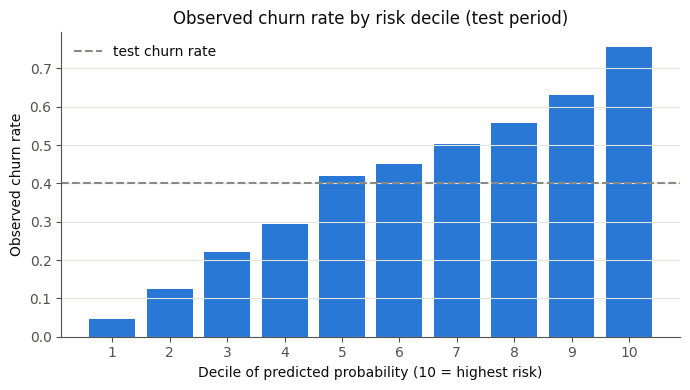

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    gain_table.index, gain_table["churn_rate"], color=SEQUENTIAL_BLUES[2],
)
ax.axhline(
    test_df["churn"].mean(), color=COLOR_NEUTRAL, linestyle="--",
    linewidth=1.5, label="test churn rate",
)
ax.set_xticks(gain_table.index)
ax.set_xlabel("Decile of predicted probability (10 = highest risk)")
ax.set_ylabel("Observed churn rate")
ax.set_title("Observed churn rate by risk decile (test period)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(
    "../report/figures/ch6_gain_by_decile.png", dpi=150,
    bbox_inches="tight",
)
plt.show()

### Calibration

Reliability curve of the raw and the calibrated probabilities
over the whole test period.

In [30]:
y_test = test_df["churn"].to_numpy()
scores_final = test_df["score_final_model"].to_numpy()
preds_final = (scores_final >= 0.5).astype(int)

classification_metrics = pd.Series({
    "churn_rate": y_test.mean(),
    "roc_auc": roc_auc_score(y_test, scores_final),
    "pr_auc": average_precision_score(y_test, scores_final),
    "precision_at_0.5": precision_score(y_test, preds_final),
    "recall_at_0.5": recall_score(y_test, preds_final),
    "f1_at_0.5": f1_score(y_test, preds_final),
})
classification_metrics.round(3)

churn_rate          0.401
roc_auc             0.759
pr_auc              0.654
precision_at_0.5    0.589
recall_at_0.5       0.694
f1_at_0.5           0.637
dtype: float64

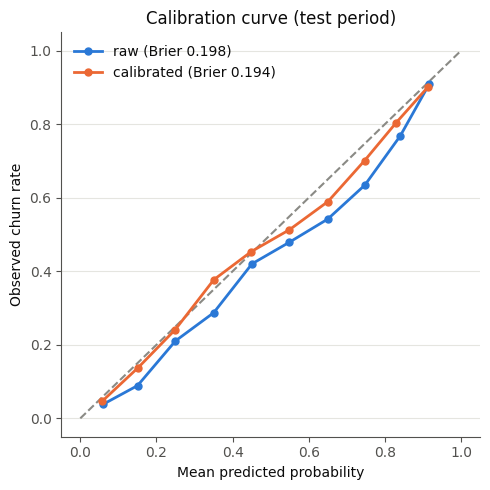

test_churn_rate      0.4005
mean_p_raw           0.4675
mean_p_calibrated    0.4179
brier_raw            0.1984
brier_calibrated     0.1941
dtype: float64

In [31]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color=COLOR_NEUTRAL, linestyle="--", linewidth=1.5)
brier = {}
for label, col, color in [
    ("raw", "score_final_model", COLOR_EXISTING),
    ("calibrated", "score_final_model_calibrated", COLOR_NEW),
]:
    brier[label] = brier_score_loss(y_test, test_df[col])
    frac_pos, mean_pred = calibration_curve(y_test, test_df[col], n_bins=10)
    ax.plot(
        mean_pred, frac_pos, color=color, marker="o", markersize=5,
        linewidth=2, label=f"{label} (Brier {brier[label]:.3f})",
    )
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed churn rate")
ax.set_title("Calibration curve (test period)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(
    "../report/figures/ch9_calibration_curve.png", dpi=150,
    bbox_inches="tight",
)
plt.show()
pd.Series({
    "test_churn_rate": y_test.mean(),
    "mean_p_raw": test_df["score_final_model"].mean(),
    "mean_p_calibrated": test_df["score_final_model_calibrated"].mean(),
    "brier_raw": brier["raw"],
    "brier_calibrated": brier["calibrated"],
}).round(4)

### Interpretability

SHAP values for the final refit model on a sample of up to 1,000
test rows (`LinearExplainer` for Logistic Regression,
`TreeExplainer` for tree models). These are associations the model
has learned, not causal effects.

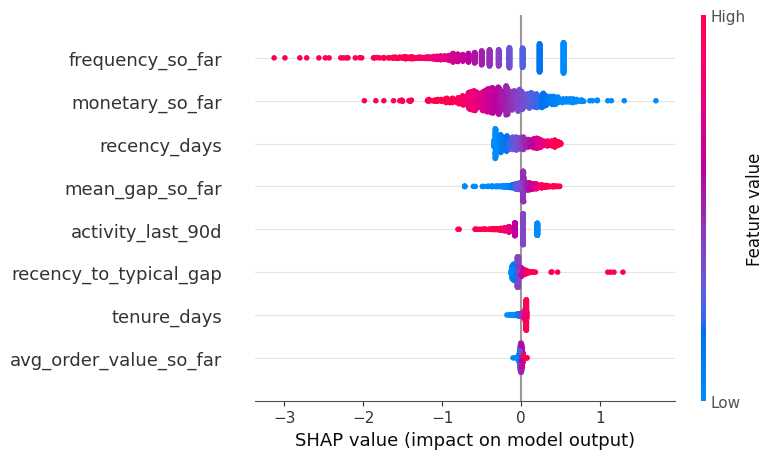

In [32]:
sample_test = test_df.sample(n=min(1000, len(test_df)), random_state=0)
X_sample = pd.DataFrame(
    final_scaler.transform(
        final_imputer.transform(
            prepare_features(sample_test, selected_features)
        )
    ),
    columns=selected_features,
)

if best_algorithm == "logistic_regression":
    background_sample = refit_train_df.sample(
        n=min(200, len(refit_train_df)), random_state=0
    )
    background = final_scaler.transform(final_imputer.transform(
        prepare_features(background_sample, selected_features)
    ))
    explainer = shap.LinearExplainer(
        final_model, background, feature_names=selected_features
    )
else:
    explainer = shap.TreeExplainer(final_model)

shap_values = explainer(X_sample)
if (
    hasattr(shap_values, "values")
    and np.ndim(shap_values.values) == 3
):
    shap_values = shap_values[..., 1]

shap.plots.beeswarm(shap_values, show=False)
plt.tight_layout()
plt.savefig(
    "../report/figures/ch8_shap_summary.png", dpi=150,
    bbox_inches="tight",
)
plt.show()

### Save the model

The fitted model, preprocessing, calibration offset and risk-band
cut-offs, loaded by `notebooks/05_evaluation.ipynb` (which
adds the expected-loss parameters of Section 7.11).

In [33]:
model_artifact = {
    "model_version": MODEL_VERSION,
    "imputer": final_imputer,
    "scaler": final_scaler,
    "model": final_model,
    "features": selected_features,
    "training_scheme": (
        "all_weekly_rows_weighted_1_over_n" if use_weighted_scheme
        else "episode_cooldown"
    ),
    "log_features": LOG_FEATURES,
    "calibration_offset": CALIBRATION_OFFSET,
    "risk_band_edges": risk_band_edges,
    "train_snapshot_end": val_end,
    "sklearn_version": sklearn.__version__,
}

os.makedirs("../models", exist_ok=True)
model_path = f"../models/churn_model_h{H}.joblib"
joblib.dump(model_artifact, model_path)
print(f"Saved model to {model_path}")

Saved model to ../models/churn_model_h90.joblib
